In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

partidas = 1000
turnos = 100

sectores = [1, 2, 3, 4, 5]

frutas = ["manzana", "naranja", "uvas", "sandia"]

valores_frutas = {
    "manzana": 1,
    "naranja": 2,
    "uvas": 3,
    "sandia": 5
}

cantidades = [0, 1, 2, 3, 4]

prob_cantidad = {
    1: [0.05, 0.15, 0.45, 0.25, 0.10],
    2: [0.10, 0.20, 0.30, 0.30, 0.10],
    3: [0.25, 0.35, 0.25, 0.10, 0.05],
    4: [0.05, 0.10, 0.20, 0.35, 0.30],
    5: [0.15, 0.15, 0.25, 0.25, 0.20]
}

prob_frutas = {
    1: [0.65, 0.20, 0.10, 0.05],
    2: [0.20, 0.40, 0.25, 0.15],
    3: [0.40, 0.30, 0.20, 0.10],
    4: [0.10, 0.15, 0.25, 0.50],
    5: [0.25, 0.25, 0.25, 0.25]
}



def entorno(sector):

    cantidad = np.random.choice(
        cantidades,
        p=prob_cantidad[sector]
    )

    if cantidad == 0:
        return 0, []

    frutas_obtenidas = np.random.choice(
        frutas,
        size=cantidad,
        p=prob_frutas[sector]
    )

    recompensa = sum(
        valores_frutas[fruta]
        for fruta in frutas_obtenidas
    )

    return recompensa, frutas_obtenidas



def softmax(x):

    exp_x = np.exp(x - np.max(x))

    return exp_x / sum(exp_x)


alpha_A = 0.95
epsilon_A = 0.1

alpha_B = 0.1



Q = {}
H = {}


def inicializar_estado(estado):

    if estado not in Q:
        Q[estado] = {sector: 0 for sector in sectores}

    if estado not in H:
        H[estado] = np.zeros(len(sectores))


print("Entorno configurado correctamente.")

Entorno configurado correctamente.


In [3]:


def elegir_accion_A(estado):

    inicializar_estado(estado)

    if np.random.uniform(0, 1) < epsilon_A:

        accion = np.random.choice(sectores)

    else:

        maxQ = -100

        mejores_acciones = []

        for sector in sectores:

            if Q[estado][sector] > maxQ:

                maxQ = Q[estado][sector]
                mejores_acciones = [sector]

            elif Q[estado][sector] == maxQ:

                mejores_acciones.append(sector)

        accion = np.random.choice(mejores_acciones)

    return accion



def elegir_accion_B(estado):

    inicializar_estado(estado)

    pi = softmax(H[estado])

    accion = np.random.choice(
        sectores,
        p=pi
    )

    return accion


print("Métodos de decisión configurados correctamente.")

Métodos de decisión configurados correctamente.


In [7]:
puntos_medios_A = np.zeros(turnos)
puntos_medios_B = np.zeros(turnos)

recompensas_medias_A = np.zeros(turnos)
recompensas_medias_B = np.zeros(turnos)

puntos_finales_A = []
puntos_finales_B = []

historial_primera_partida = []
historial_ultima_partida = []


for partida in range(partidas):

    posicion_A = np.random.choice(sectores)
    posicion_B = np.random.choice(sectores)

    puntos_A = 0
    puntos_B = 0

    contador_juntos = 0

    recompensas_B = []

    registro_partida = []

    for turno in range(turnos):

        estado = (
            posicion_A,
            posicion_B,
            contador_juntos
        )

        inicializar_estado(estado)

        accion_A = elegir_accion_A(estado)

        accion_B = elegir_accion_B(estado)

        posicion_anterior_A = posicion_A
        posicion_anterior_B = posicion_B

        posicion_A = accion_A
        posicion_B = accion_B

        if posicion_A == posicion_B:

            if (
                posicion_anterior_A == posicion_anterior_B
                and posicion_A == posicion_anterior_A
                and contador_juntos > 0
            ):

                contador_juntos = min(
                    contador_juntos + 1,
                    4
                )

            else:

                contador_juntos = 1

        else:

            contador_juntos = 0

        recompensa_A, frutas_A = entorno(posicion_A)

        recompensa_B, frutas_B = entorno(posicion_B)

        if contador_juntos >= 4:

            recompensa_A *= 0.5
            recompensa_B *= 0.5

        puntos_A += recompensa_A
        puntos_B += recompensa_B

        Q[estado][accion_A] += alpha_A * (
            recompensa_A - Q[estado][accion_A]
        )

        recompensas_B.append(recompensa_B)

        recompensa_media_B = np.mean(recompensas_B)

        pi = softmax(H[estado])

        for j in range(len(sectores)):

            if sectores[j] == accion_B:

                H[estado][j] += (
                    alpha_B
                    * (recompensa_B - recompensa_media_B)
                    * (1 - pi[j])
                )

            else:

                H[estado][j] -= (
                    alpha_B
                    * (recompensa_B - recompensa_media_B)
                    * pi[j]
                )

        registro = {
            "turno": turno + 1,

            "estado": estado,

            "sector_A": posicion_A,
            "sector_B": posicion_B,

            "accion_A": accion_A,
            "accion_B": accion_B,

            "frutas_A": list(frutas_A),
            "frutas_B": list(frutas_B),

            "recompensa_A": recompensa_A,
            "recompensa_B": recompensa_B,

            "puntos_A": puntos_A,
            "puntos_B": puntos_B,

            "contador_juntos": contador_juntos,

            "castigo": contador_juntos >= 4
        }

        registro_partida.append(registro)

        puntos_medios_A[turno] += puntos_A
        puntos_medios_B[turno] += puntos_B

        recompensas_medias_A[turno] += recompensa_A
        recompensas_medias_B[turno] += recompensa_B

    # Guardar el historial de la primera partida
    if partida == 0:

        historial_primera_partida = registro_partida.copy()

    # Guardar el historial de la última partida
    if partida == partidas - 1:

        historial_ultima_partida = registro_partida.copy()

    puntos_finales_A.append(puntos_A)
    puntos_finales_B.append(puntos_B)


puntos_medios_A /= partidas
puntos_medios_B /= partidas

recompensas_medias_A /= partidas
recompensas_medias_B /= partidas


print("Entrenamiento finalizado correctamente.")

Entrenamiento finalizado correctamente.


RESULTADOS DEL ENTRENAMIENTO
------------------------------------
Promedio de puntos Agente 1: 674.28
Promedio de puntos Agente 2: 988.77
Mejor resultado Agente 1: 904.50
Mejor resultado Agente 2: 1156.00

ULTIMA PARTIDA
------------------------------------
Turno  Sector A  Sector B  Recomp. A   Recomp. B   Puntos A    Puntos B    Juntos  Castigo 


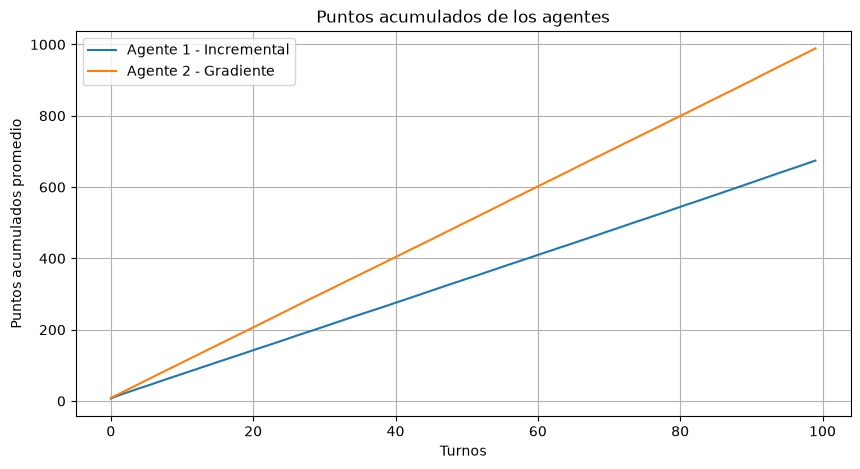

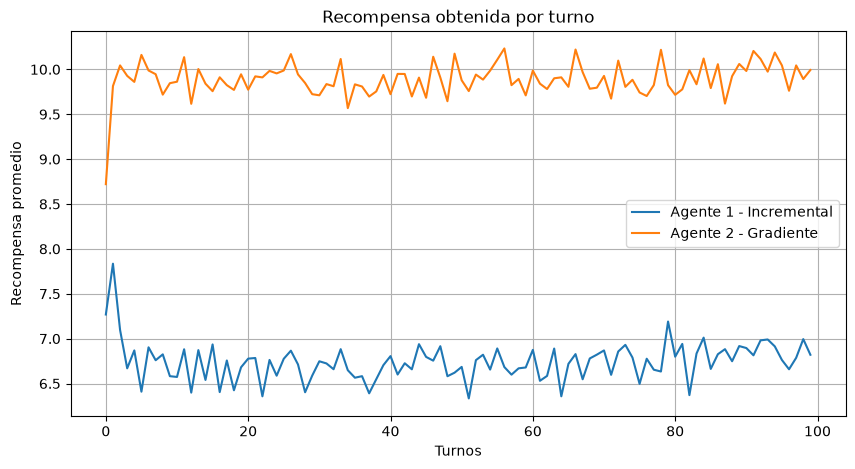

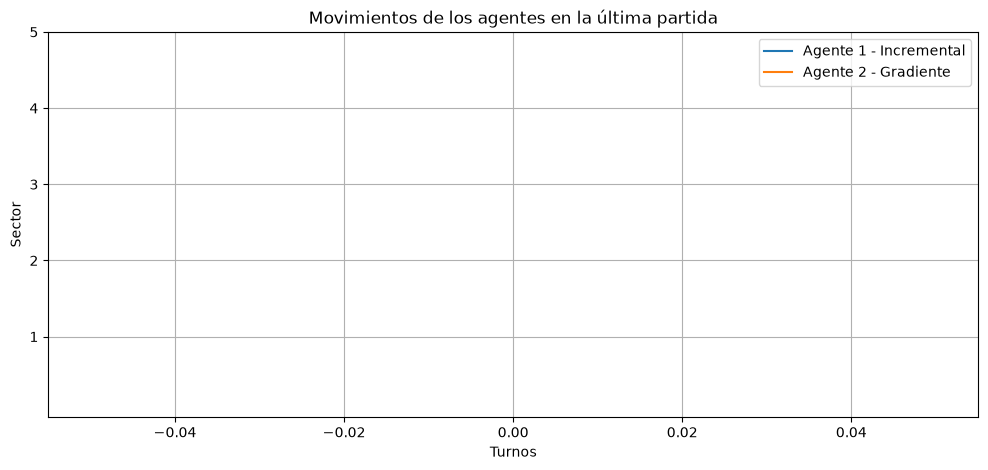

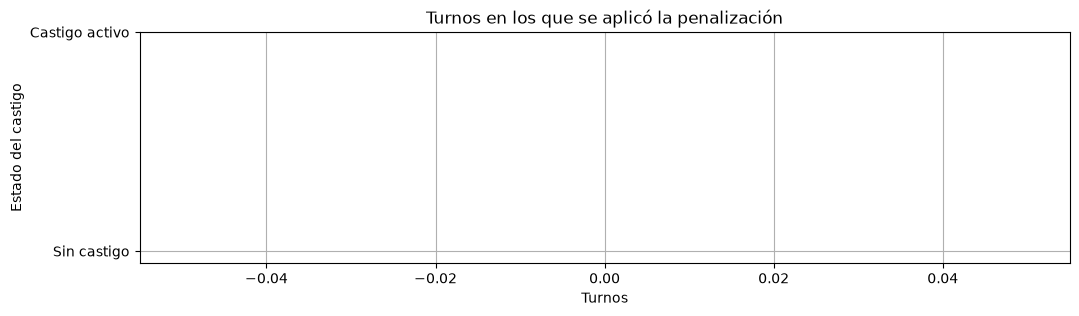

In [8]:


print("RESULTADOS DEL ENTRENAMIENTO")
print("------------------------------------")

print(
    f"Promedio de puntos Agente 1: "
    f"{np.mean(puntos_finales_A):.2f}"
)

print(
    f"Promedio de puntos Agente 2: "
    f"{np.mean(puntos_finales_B):.2f}"
)

print(
    f"Mejor resultado Agente 1: "
    f"{np.max(puntos_finales_A):.2f}"
)

print(
    f"Mejor resultado Agente 2: "
    f"{np.max(puntos_finales_B):.2f}"
)



print("\nULTIMA PARTIDA")
print("------------------------------------")

print(
    f"{'Turno':<7}"
    f"{'Sector A':<10}"
    f"{'Sector B':<10}"
    f"{'Recomp. A':<12}"
    f"{'Recomp. B':<12}"
    f"{'Puntos A':<12}"
    f"{'Puntos B':<12}"
    f"{'Juntos':<8}"
    f"{'Castigo':<8}"
)

for r in historial:

    print(
        f"{r['turno']:<7}"
        f"{r['sector_A']:<10}"
        f"{r['sector_B']:<10}"
        f"{r['recompensa_A']:<12.2f}"
        f"{r['recompensa_B']:<12.2f}"
        f"{r['puntos_A']:<12.2f}"
        f"{r['puntos_B']:<12.2f}"
        f"{r['contador_juntos']:<8}"
        f"{str(r['castigo']):<8}"
    )



plt.figure(figsize=(10, 5))

plt.plot(
    puntos_medios_A,
    label="Agente 1 - Incremental"
)

plt.plot(
    puntos_medios_B,
    label="Agente 2 - Gradiente"
)

plt.xlabel("Turnos")
plt.ylabel("Puntos acumulados promedio")

plt.title("Puntos acumulados de los agentes")

plt.legend()
plt.grid(True)
plt.show()



plt.figure(figsize=(10, 5))

plt.plot(
    recompensas_medias_A,
    label="Agente 1 - Incremental"
)

plt.plot(
    recompensas_medias_B,
    label="Agente 2 - Gradiente"
)

plt.xlabel("Turnos")
plt.ylabel("Recompensa promedio")

plt.title("Recompensa obtenida por turno")

plt.legend()
plt.grid(True)
plt.show()



turnos_grafica = [
    r["turno"] for r in historial
]

sectores_A = [
    r["sector_A"] for r in historial
]

sectores_B = [
    r["sector_B"] for r in historial
]

plt.figure(figsize=(12, 5))

plt.step(
    turnos_grafica,
    sectores_A,
    where="mid",
    label="Agente 1 - Incremental"
)

plt.step(
    turnos_grafica,
    sectores_B,
    where="mid",
    label="Agente 2 - Gradiente"
)

plt.yticks(sectores)

plt.xlabel("Turnos")
plt.ylabel("Sector")

plt.title("Movimientos de los agentes en la última partida")

plt.legend()
plt.grid(True)
plt.show()



castigos = [
    1 if r["castigo"] else 0
    for r in historial
]

plt.figure(figsize=(12, 3))

plt.step(
    turnos_grafica,
    castigos,
    where="mid"
)

plt.yticks([0, 1], ["Sin castigo", "Castigo activo"])

plt.xlabel("Turnos")
plt.ylabel("Estado del castigo")

plt.title("Turnos en los que se aplicó la penalización")

plt.grid(True)
plt.show()

In [9]:
import pandas as pd

tabla_primera_partida = pd.DataFrame(
    historial_primera_partida
)

print("RESULTADOS DE LA PRIMERA PARTIDA")

display(tabla_primera_partida)

RESULTADOS DE LA PRIMERA PARTIDA


,turno,estado,sector_A,sector_B,accion_A,accion_B,frutas_A,frutas_B,recompensa_A,recompensa_B,puntos_A,puntos_B,contador_juntos,castigo
0,1,"(1, 1, 0)",2,3,2,3,[],[],0,0,0,0,0,False
1,2,"(2, 3, 0)",4,4,4,4,"[uvas, sandia, sandia]",[],13,0,13,0,1,False
2,3,"(4, 4, 1)",4,4,4,4,"[sandia, sandia]",[],10,0,23,0,2,False
3,4,"(4, 4, 2)",3,4,3,4,"[naranja, manzana]",[sandia],3,5,26,5,0,False
4,5,"(3, 4, 0)",4,4,4,4,"[uvas, uvas, uvas]","[uvas, sandia]",9,8,35,13,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,"(4, 4, 3)",2,4,2,4,"[naranja, naranja]","[sandia, naranja, sandia]",4,12,781,925,0,False
96,97,"(2, 4, 0)",4,4,4,4,"[sandia, sandia]","[uvas, uvas, sandia]",10,11,791,936,1,False
97,98,"(4, 4, 1)",4,4,4,4,"[manzana, manzana, uvas, sandia]","[uvas, manzana, sandia]",10,9,801,945,2,False
98,99,"(4, 4, 2)",4,4,4,4,"[sandia, sandia]","[uvas, naranja, sandia]",10,10,811,955,3,False


In [10]:
tabla_ultima_partida = pd.DataFrame(
    historial_ultima_partida
)

print("RESULTADOS DE LA ÚLTIMA PARTIDA")

display(tabla_ultima_partida)

RESULTADOS DE LA ÚLTIMA PARTIDA


,turno,estado,sector_A,sector_B,accion_A,accion_B,frutas_A,frutas_B,recompensa_A,recompensa_B,puntos_A,puntos_B,contador_juntos,castigo
0,1,"(4, 5, 0)",4,4,4,4,"[uvas, uvas, sandia, uvas]","[sandia, naranja, sandia]",14,12,14,12,1,False
1,2,"(4, 4, 1)",4,4,4,4,"[sandia, sandia, sandia, manzana]","[sandia, sandia, uvas]",16,13,30,25,2,False
2,3,"(4, 4, 2)",4,4,4,4,"[naranja, uvas, manzana]","[sandia, sandia]",6,10,36,35,3,False
3,4,"(4, 4, 3)",2,4,2,4,"[naranja, naranja]","[uvas, uvas, sandia, sandia]",4,16,40,51,0,False
4,5,"(2, 4, 0)",4,4,4,4,"[naranja, sandia]","[uvas, sandia, manzana]",7,9,47,60,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,"(4, 4, 1)",5,4,5,4,[manzana],[naranja],1,2,743,904,0,False
96,97,"(5, 4, 0)",3,4,3,4,"[manzana, naranja]","[sandia, sandia]",3,10,746,914,0,False
97,98,"(3, 4, 0)",4,4,4,4,[naranja],"[uvas, sandia, uvas, uvas]",2,14,748,928,1,False
98,99,"(4, 4, 1)",5,4,5,4,"[uvas, uvas]","[sandia, manzana]",6,6,754,934,0,False
